In [3]:

import pandas as pd
from ydata_profiling import ProfileReport

# Load CSV file
df = pd.read_csv("../data/orginal/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# # Generate automatic report
# profile = ProfileReport(
#     df,
#     title="My Dataset Analysis Report",
#     explorative=True
# )

# # Export report to HTML
# profile.to_file("../report/data_report.html")

# print("Report created: data_report.html")


d:\My all project\Customer Churn Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\sheik\AppData\Local\Temp\ipykernel_9388\3615783095.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [4]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

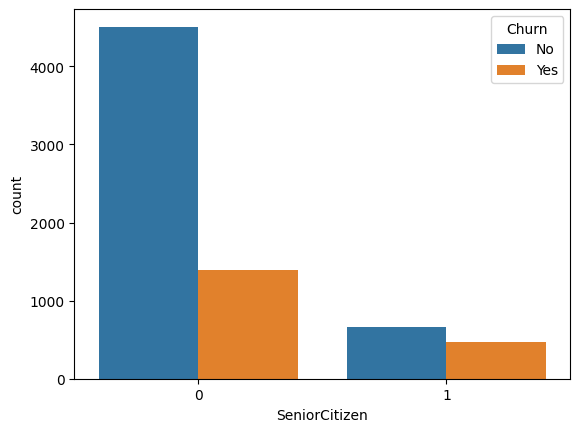

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# plt.plot(df['SeniorCitizen'],df['Churn'],hue=df['Churn'],kind='bar')
sns.countplot(data=df, x='SeniorCitizen',hue='Churn')
plt.show()

<Axes: xlabel='Partner', ylabel='count'>

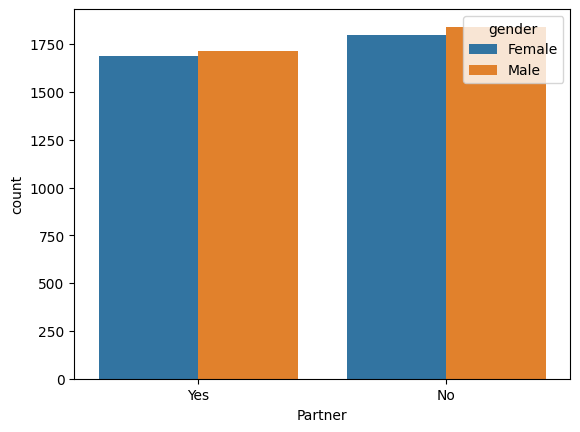

In [6]:
sns.countplot(data=df, x='Partner', hue='gender')

In [7]:
# Find categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns

# Show unique values
# for col in categorical_cols:
#     # print(f"\nColumn: {col}")
#     print(df[col].value_counts(dropna=False))
categorical_cols

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='object')

In [8]:
df[categorical_cols].value_counts()

customerID  gender  Partner  Dependents  PhoneService  MultipleLines     InternetService  OnlineSecurity  OnlineBackup  DeviceProtection  TechSupport  StreamingTV  StreamingMovies  Contract        PaperlessBilling  PaymentMethod     TotalCharges  Churn
0002-ORFBO  Female  Yes      Yes         Yes           No                DSL              No              Yes           No                Yes          Yes          No               One year        Yes               Mailed check      593.3         No       1
0003-MKNFE  Male    No       No          Yes           Yes               DSL              No              No            No                No           No           Yes              Month-to-month  No                Mailed check      542.4         No       1
0004-TLHLJ  Male    No       No          Yes           No                Fiber optic      No              No            Yes               No           No           No               Month-to-month  Yes               Electronic check

In [9]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [10]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [11]:
from main import y
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [12]:
import pandas as pd
df = pd.read_csv('../outputs/baseline_model_comparison.csv')
df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.821859,0.687117,0.600536,0.640916,0.862245
1,SVC,0.755855,0.525394,0.804290,0.635593,0.844903
2,Gradient Boosting,0.809794,0.673267,0.546917,0.603550,0.859688
3,Random Forest,0.775727,0.567376,0.643432,0.603015,0.837051
4,XGBoost,0.807665,0.671141,0.536193,0.596125,0.861587
5,Decision Tree,0.725337,0.481283,0.482574,0.481928,0.647874


In [32]:
import pandas as pd
df = pd.read_csv('../report/model_comparison.csv')
df

,Unnamed: 0,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Best_CV_ROC_AUC,Best_Params
0,1,Gradient Boosting,0.25,0.743790,0.509740,0.841823,0.634985,0.859266,0.843380,"{'model__subsample': 1.0, 'model__n_estimators..."
1,0,XGBoost,0.25,0.740951,0.506369,0.852547,0.635365,0.860693,0.843035,"{'model__subsample': 0.8, 'model__n_estimators..."
2,2,Logistic Regression,0.30,0.776437,0.554104,0.796247,0.653465,0.861838,0.837086,"{'model__solver': 'lbfgs', 'model__class_weigh..."
3,3,Random Forest,0.30,0.760114,0.530756,0.809651,0.641189,0.857034,0.836004,"{'model__n_estimators': 200, 'model__min_sampl..."
4,4,SVC,0.25,0.748758,0.515651,0.839142,0.638776,0.851706,0.827302,"{'model__kernel': 'rbf', 'model__class_weight'..."


In [14]:
from data_preprocessing_pipeline import process_data
import pandas as pd 
df = pd.read_csv('../data/orginal/WA_Fn-UseC_-Telco-Customer-Churn.csv')

X = df.drop(columns=['customerID','Churn'])

X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [15]:
process = process_data(X)
x_porcess = process.fit_transform(X)

In [16]:
x_porcess

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 133817 stored elements and shape (7043, 6575)>

In [17]:
feature_name = process.get_feature_names_out()
feature_name

array(['num__SeniorCitizen', 'num__tenure', 'num__MonthlyCharges', ...,
       'cat__TotalCharges_999.45', 'cat__TotalCharges_999.8',
       'cat__TotalCharges_999.9'], shape=(6575,), dtype=object)

In [18]:
process = process_data(X)

X_processed = process.fit_transform(X)

feature_name = process.get_feature_names_out()

print("Input shape:", X.shape)
print("Output type:", type(X_processed))
print("Output shape:", X_processed.shape)
print("Number of feature names:", len(feature_name))

Input shape: (7043, 19)
Output type: <class 'scipy.sparse._csr.csr_matrix'>
Output shape: (7043, 6575)
Number of feature names: 6575


In [19]:
X_processed_dense = x_porcess.toarray() #sprace matrix to convarting array

process_data_frame = pd.DataFrame(
    X_processed_dense,
    columns=feature_name,
    index=X.index
)

process_data_frame

,num__SeniorCitizen,num__tenure,num__MonthlyCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,cat__PhoneService_No,...,cat__TotalCharges_995.35,cat__TotalCharges_996.45,cat__TotalCharges_996.85,cat__TotalCharges_996.95,cat__TotalCharges_997.65,cat__TotalCharges_997.75,cat__TotalCharges_998.1,cat__TotalCharges_999.45,cat__TotalCharges_999.8,cat__TotalCharges_999.9
0,-0.439916,-1.277445,-1.160323,1.0,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.439916,0.066327,-0.259629,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.439916,-1.236724,-0.362660,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.439916,0.514251,-0.746535,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.439916,-1.236724,0.197365,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,-0.439916,-0.340876,0.665992,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7039,-0.439916,1.613701,1.277533,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7040,-0.439916,-0.870241,-1.168632,1.0,0.0,0.0,1.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7041,2.273159,-1.155283,0.320338,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
y = df['Churn'].map({
    "Yes": 1,
    "No": 0
})

process_data_frame['Churn'] = y

In [21]:
process_data_frame.to_csv('../data/process/WA_Fn-UseC_-Telco-Customer-Churn-process.csv',index=False)

In [22]:
process_data_frame.head()

,num__SeniorCitizen,num__tenure,num__MonthlyCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,cat__PhoneService_No,...,cat__TotalCharges_996.45,cat__TotalCharges_996.85,cat__TotalCharges_996.95,cat__TotalCharges_997.65,cat__TotalCharges_997.75,cat__TotalCharges_998.1,cat__TotalCharges_999.45,cat__TotalCharges_999.8,cat__TotalCharges_999.9,Churn
0,-0.439916,-1.277445,-1.160323,1.0,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,-0.439916,0.066327,-0.259629,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,-0.439916,-1.236724,-0.362660,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,-0.439916,0.514251,-0.746535,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,-0.439916,-1.236724,0.197365,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1


In [23]:
import pandas as pd
df = pd.read_csv('../data/orginal/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [24]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [25]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [26]:
df_columns_name = df.columns.tolist()
print(len(df_columns_name))
print(df_columns_name)

21
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [27]:
print(df['MonthlyCharges'].describe())
print(df['TotalCharges'].describe())

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64
count     7043
unique    6531
top       20.2
freq        11
Name: TotalCharges, dtype: object


In [28]:
print(df[df['TotalCharges'].isna()])

Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []

[0 rows x 21 columns]


In [29]:
for columns in df_columns_name:
    if columns in ['customerID', 'MonthlyCharges', 'TotalCharges', 'Churn', 'tenure']:
        pass
    else:
        print(df[columns].value_counts())

gender
Male      3555
Female    3488
Name: count, dtype: int64
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
Partner
No     3641
Yes    3402
Name: count, dtype: int64
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: c

In [30]:
df_columns_name

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [31]:
import pandas as pd
df = pd.read_csv("../data/orginal/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 
